# Assignment 1 — training pipeline

**Decision supported:** before each quarter, an online giftware wholesaler sends a
10% win-back voucher to customers it expects to *lapse* (no order in the next 90 days).
The model ranks active customers by lapse probability; the threshold comes from the
voucher economics. Full reasoning is in `REPORT.md`.

Run via `uv run python main.py train`. Everything here reads only the committed
`data/online_retail_ii.csv.gz` and writes to `artifacts/`.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler
from torch import nn

from common import LogisticRegression, break_even_threshold, voucher_profit

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_default_dtype(torch.float64)  # float64 so the three fits can agree to many decimals

DATA = Path("data/online_retail_ii.csv.gz")
ART = Path("artifacts")
ART.mkdir(exist_ok=True)

## Settings that come from the business framing

In [2]:
LOOKBACK_DAYS = 180  # history used to describe a customer at a cutoff
HORIZON_DAYS = 90    # lapse = no order in the 90 days after the cutoff

# Quarterly snapshots. The data starts 2009-12-01, so 2010-06-01 is the first cutoff
# with a full 180-day history; it ends 2011-12-09, so 2011-09-01 is the last cutoff
# whose 90-day outcome is fully observed.
TRAIN_CUTOFFS = ["2010-06-01", "2010-09-01", "2010-12-01", "2011-03-01"]
VAL_CUTOFF = "2011-06-01"
TEST_CUTOFF = "2011-09-01"

# Voucher economics
DISCOUNT = 0.10        # voucher = 10% off the next order
MARGIN = 0.30          # gross margin on the goods
SAVE_RATE = 0.15       # share of would-be lapsers the voucher brings back
RETAINED_QUARTERS = 4  # a won-back customer keeps ordering for about a year
MAIL_COST = 1.0        # GBP per voucher sent
COSTS = dict(discount=DISCOUNT, margin=MARGIN, save_rate=SAVE_RATE,
             retained_quarters=RETAINED_QUARTERS, mail_cost=MAIL_COST)

T_BREAK_EVEN = break_even_threshold(DISCOUNT, MARGIN, SAVE_RATE, RETAINED_QUARTERS)
print(f"break-even lapse probability: {T_BREAK_EVEN:.3f}")

break-even lapse probability: 0.377


## Load and clean

In [3]:
raw = pd.read_csv(DATA, dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])

steps = {"lines with a customer (committed file)": len(raw)}
df = raw.drop_duplicates()
steps["after dropping exact duplicate lines"] = len(df)
df = df[df["StockCode"].str.match(r"^\d{5}")]  # real products; drops POST, M, ADJUST, BANK CHARGES, ...
steps["after keeping product codes only"] = len(df)
df = df[df["Price"] > 0]
steps["after dropping zero-price lines"] = len(df)

df = df.rename(columns={"Customer ID": "customer"})
df["value"] = df["Quantity"] * df["Price"]
df["is_cancel"] = df["Invoice"].str.startswith("C")
df["is_xmas"] = df["Description"].fillna("").str.upper().str.contains("CHRISTMAS|XMAS")

buys = df[~df["is_cancel"] & (df["Quantity"] > 0)]
cancels = df[df["is_cancel"]]

# one row per order
orders = (
    buys.groupby(["customer", "Invoice"])
    .agg(date=("InvoiceDate", "min"), value=("value", "sum"), lines=("StockCode", "size"))
    .reset_index()
)
country = df.groupby("customer")["Country"].agg(lambda s: s.mode().iloc[0])

pd.Series(steps, name="rows").to_frame()

,rows
lines with a customer (committed file),824364
after dropping exact duplicate lines,797885
after keeping product codes only,794223
after dropping zero-price lines,794163


## Customer snapshots

At each cutoff `t`, the population is every customer with at least one order in
`[t - 180d, t)`. Features use only that window; the label uses only `[t, t + 90d)`.

In [4]:
SEASON_OF_MONTH = {3: "spring", 6: "summer", 9: "autumn", 12: "winter"}


def snapshot(cutoff: str) -> pd.DataFrame:
    t = pd.Timestamp(cutoff)
    start, end = t - pd.Timedelta(days=LOOKBACK_DAYS), t + pd.Timedelta(days=HORIZON_DAYS)

    o = orders[(orders["date"] >= start) & (orders["date"] < t)]
    g = o.groupby("customer")
    s = pd.DataFrame({
        "n_orders": g.size(),
        "revenue": g["value"].sum(),
        "lines_per_order": g["lines"].mean(),
        "first": g["date"].min(),
        "last": g["date"].max(),
    })
    s["recency_days"] = (t - s["last"]).dt.days
    s["days_since_first"] = (t - s["first"]).dt.days
    s["one_time"] = (s["n_orders"] == 1).astype(int)
    gap = (s["last"] - s["first"]).dt.days / (s["n_orders"] - 1)
    # how late the customer is compared with their own rhythm (0 for one-time buyers)
    s["log_overdue"] = (np.log1p(s["recency_days"]) - np.log1p(gap)).where(s["n_orders"] > 1, 0.0)
    recent = o[o["date"] >= t - pd.Timedelta(days=60)].groupby("customer").size()
    s["recent_share"] = recent.reindex(s.index, fill_value=0) / s["n_orders"]

    b = buys[(buys["InvoiceDate"] >= start) & (buys["InvoiceDate"] < t)]
    s["n_products"] = b.groupby("customer")["StockCode"].nunique().reindex(s.index)
    xmas_value = b[b["is_xmas"]].groupby("customer")["value"].sum()
    s["xmas_share"] = xmas_value.reindex(s.index, fill_value=0) / s["revenue"]

    c = cancels[(cancels["InvoiceDate"] >= start) & (cancels["InvoiceDate"] < t)]
    returned = -c.groupby("customer")["value"].sum()
    s["return_rate"] = (returned.reindex(s.index, fill_value=0) / s["revenue"]).clip(0, 1)

    s["uk"] = (country.reindex(s.index) == "United Kingdom").astype(int)
    s["quarterly_spend"] = s["revenue"] * HORIZON_DAYS / LOOKBACK_DAYS  # usual spend per quarter

    future = orders[(orders["date"] >= t) & (orders["date"] < end)]["customer"].unique()
    s["lapsed"] = (~s.index.isin(future)).astype(int)
    s["cutoff"] = t
    s["season"] = SEASON_OF_MONTH[t.month]
    return s.drop(columns=["first", "last"]).reset_index()


snaps = []
for split, cutoffs in [("train", TRAIN_CUTOFFS), ("val", [VAL_CUTOFF]), ("test", [TEST_CUTOFF])]:
    for c in cutoffs:
        snaps.append(snapshot(c).assign(split=split))
snaps = pd.concat(snaps, ignore_index=True)

snaps.groupby(["split", "cutoff"], sort=False).agg(customers=("lapsed", "size"), lapse_rate=("lapsed", "mean")).round(3)

customers  lapse_rate
split cutoff                           
train 2010-06-01       2652       0.500
      2010-09-01       2822       0.380
      2010-12-01       3465       0.620
      2011-03-01       3338       0.576
val   2011-06-01       2658       0.500
test  2011-09-01       2768       0.393

## Features

Money and counts are heavy-tailed (a few wholesalers order 100x the median), so they
enter as logs. Season dummies (reference: summer) let the base rate move with the
quarter, and `xmas_x_autumn` lets Christmas-heavy buyers behave differently in the
pre-Christmas quarter.

In [5]:
def build_features(s: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=s.index)
    X["log_recency"] = np.log1p(s["recency_days"])
    X["log_orders"] = np.log1p(s["n_orders"])
    X["log_revenue"] = np.log1p(s["revenue"])
    X["log_avg_order"] = np.log(s["revenue"] / s["n_orders"])
    X["log_lines_per_order"] = np.log(s["lines_per_order"])
    X["log_products"] = np.log1p(s["n_products"])
    X["days_since_first"] = s["days_since_first"]
    X["one_time"] = s["one_time"]
    X["log_overdue"] = s["log_overdue"]
    X["recent_share"] = s["recent_share"]
    X["return_rate"] = s["return_rate"]
    X["uk"] = s["uk"]
    X["xmas_share"] = s["xmas_share"]
    for season in ["spring", "autumn", "winter"]:
        X[f"season_{season}"] = (s["season"] == season).astype(int)
    X["xmas_x_autumn"] = s["xmas_share"] * X["season_autumn"]
    return X


X_all = build_features(snaps)

FEATURE_GROUPS = {
    "RFM": ["log_recency", "log_orders", "log_revenue"],
    "+ order behaviour": ["log_avg_order", "log_lines_per_order", "log_products", "days_since_first",
                          "one_time", "log_overdue", "recent_share"],
    "+ returns & country": ["return_rate", "uk"],
    "+ season": ["season_spring", "season_autumn", "season_winter"],
    "+ christmas": ["xmas_share", "xmas_x_autumn"],
}
ALL_FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]

is_train, is_val, is_test = (snaps["split"] == s for s in ["train", "val", "test"])
y_all = snaps["lapsed"].to_numpy()
X_all[ALL_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_recency,17703.0,3.70,1.15,0.00,3.00,3.93,4.62,5.19
log_orders,17703.0,1.14,0.55,0.69,0.69,1.10,1.39,4.77
log_revenue,17703.0,6.31,1.15,0.83,5.57,6.25,7.03,12.02
log_avg_order,17703.0,5.64,0.77,0.26,5.17,5.68,6.07,11.25
log_lines_per_order,17703.0,2.72,0.93,0.00,2.23,2.83,3.33,5.61
log_products,17703.0,3.33,1.05,0.69,2.71,3.40,4.04,7.13
days_since_first,17703.0,112.82,51.39,0.00,74.00,124.00,160.00,179.00
one_time,17703.0,0.46,0.50,0.00,0.00,0.00,1.00,1.00
log_overdue,17703.0,-0.06,1.22,-5.19,-0.37,0.00,0.00,5.19
recent_share,17703.0,0.34,0.38,0.00,0.00,0.25,0.50,1.00


## Feature-group ablation (validation only)

Add one group at a time and keep it only if validation log loss improves.
Scaler is refit on the training rows each time.

In [6]:
def fit_sklearn(cols, C):
    scaler = StandardScaler().fit(X_all.loc[is_train, cols])
    model = SkLogisticRegression(C=C, tol=1e-10, max_iter=10_000)
    model.fit(scaler.transform(X_all.loc[is_train, cols]), y_all[is_train])
    return scaler, model


def val_scores(cols, C=1.0):
    scaler, model = fit_sklearn(cols, C)
    p = model.predict_proba(scaler.transform(X_all.loc[is_val, cols]))[:, 1]
    return log_loss(y_all[is_val], p), roc_auc_score(y_all[is_val], p)


rows, kept = [], []
best = np.inf
for name, group in FEATURE_GROUPS.items():
    ll, auc = val_scores(kept + group)
    keep = ll < best
    rows.append({"group": name, "n_features": len(kept + group), "val_log_loss": ll, "val_auc": auc, "kept": keep})
    if keep:
        kept, best = kept + group, ll

ablation = pd.DataFrame(rows)
FEATURES = kept
ablation.round(4)

,group,n_features,val_log_loss,val_auc,kept
0,RFM,3,0.5906,0.7484,True
1,+ order behaviour,10,0.5882,0.7497,True
2,+ returns & country,12,0.5879,0.7499,True
3,+ season,15,0.5821,0.7520,True
4,+ christmas,17,0.5820,0.7526,True


## Split and scale

One scaler, fit on the training snapshots only, shared by all three implementations.

In [7]:
scaler = StandardScaler().fit(X_all.loc[is_train, FEATURES])
X_tr, X_va, X_te = (scaler.transform(X_all.loc[m, FEATURES]) for m in [is_train, is_val, is_test])
y_tr, y_va, y_te = y_all[is_train], y_all[is_val], y_all[is_test]
n, d = X_tr.shape
print(f"train {X_tr.shape}, val {X_va.shape}, test {X_te.shape}")

train (12277, 17), val (2658, 17), test (2768, 17)


## 1. scikit-learn — tune C on validation log loss

sklearn minimises `C * sum(log loss) + 0.5 * ||w||^2` (intercept not penalised).
Dividing by `C * n` gives the same minimiser as
`mean(log loss) + (lam / 2) * ||w||^2` with `lam = 1 / (C * n)`,
which is what both PyTorch versions minimise below.

In [8]:
C_GRID = np.logspace(-4, 2, 13)
c_rows = []
for C in C_GRID:
    m = SkLogisticRegression(C=C, tol=1e-10, max_iter=10_000).fit(X_tr, y_tr)
    c_rows.append({"C": C, "val_log_loss": log_loss(y_va, m.predict_proba(X_va)[:, 1])})
c_search = pd.DataFrame(c_rows)
C_BEST = float(c_search.loc[c_search["val_log_loss"].idxmin(), "C"])
LAM = 1.0 / (C_BEST * n)

sk_model = SkLogisticRegression(C=C_BEST, tol=1e-10, max_iter=10_000).fit(X_tr, y_tr)
print(f"C = {C_BEST:.4g}  ->  lam = 1/(C n) = {LAM:.3e}")
c_search.round(5)

C = 1  ->  lam = 1/(C n) = 8.145e-05


,C,val_log_loss
0,0.00010,0.62490
1,0.00032,0.60274
2,0.00100,0.59206
3,0.00316,0.58680
4,0.01000,0.58403
5,0.03162,0.58275
6,0.10000,0.58222
7,0.31623,0.58203
8,1.00000,0.58198
9,3.16228,0.58200


## 2. PyTorch, manual loop

Raw tensors, autograd for the gradient, and the update written by hand. Stops when
the gradient norm is below `1e-8` (the problem is convex, so that point is the
unique minimum).

In [9]:
Xt_tr, Xt_va, Xt_te = (torch.tensor(a) for a in (X_tr, X_va, X_te))
yt_tr = torch.tensor(y_tr, dtype=torch.float64)


def objective(w, b, X, y, lam):
    z = X @ w + b
    data_loss = torch.mean(torch.logaddexp(torch.zeros_like(z), z) - y * z)  # = mean BCE, stable
    return data_loss + 0.5 * lam * (w @ w)


def train_manual(lr, max_epochs, tol=1e-8):
    w = torch.zeros(d, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    history = []
    for epoch in range(max_epochs):
        loss = objective(w, b, Xt_tr, yt_tr, LAM)
        loss.backward()
        with torch.no_grad():
            grad_norm = torch.sqrt(w.grad @ w.grad + b.grad @ b.grad).item()
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()
        history.append(loss.item())
        if grad_norm < tol:
            break
    return w.detach(), b.detach(), history, grad_norm

## 3. PyTorch, standard `nn.Module` + `torch.optim`

Full-batch SGD so it follows the same path as the manual loop. `weight_decay = lam`
adds `lam * w` to the gradient, i.e. the `(lam / 2) * ||w||^2` penalty — applied to
the weights only, through a separate parameter group for the bias (by default
`weight_decay` would also shrink the intercept, which sklearn does not do).

In [10]:
loss_fn = nn.BCEWithLogitsLoss()


def train_module(lr, max_epochs, tol=1e-8):
    torch.manual_seed(SEED)
    model = LogisticRegression(d)  # default random init, unlike the manual loop's zeros
    opt = torch.optim.SGD(
        [
            {"params": [model.linear.weight], "weight_decay": LAM},
            {"params": [model.linear.bias], "weight_decay": 0.0},
        ],
        lr=lr,
    )
    history = []
    for epoch in range(max_epochs):
        opt.zero_grad()
        loss = loss_fn(model(Xt_tr), yt_tr)
        loss.backward()
        with torch.no_grad():  # log the full objective (data loss + penalty) before stepping
            w = model.linear.weight.squeeze(0)
            history.append(loss.item() + 0.5 * LAM * (w @ w).item())
            grad_w = model.linear.weight.grad.squeeze(0) + LAM * w
            grad_norm = torch.sqrt(grad_w @ grad_w + model.linear.bias.grad @ model.linear.bias.grad).item()
        opt.step()
        if grad_norm < tol:
            break
    return model, history, grad_norm

### Learning rate

Same objective for every learning rate, so the learning rate only decides how fast
(or whether) we reach the minimum. Each candidate gets the same budget; we keep the
one with the lowest training objective (validation loss is printed to show it adds
nothing once runs converge).

In [11]:
LR_GRID = [0.05, 0.1, 0.5, 1.0, 2.0, 4.0]
BUDGET = 2_000
def safe_log_loss(y, p):
    return log_loss(y, np.clip(p, 1e-12, 1 - 1e-12)) if np.all(np.isfinite(p)) else np.nan  # nan = diverged


lr_rows = []
for lr in LR_GRID:
    w, b, h, g = train_manual(lr, BUDGET, tol=0)
    p_va = torch.sigmoid(Xt_va @ w + b).numpy()
    m, h2, g2 = train_module(lr, BUDGET, tol=0)
    with torch.no_grad():
        p_va2 = torch.sigmoid(m(Xt_va)).numpy()
    lr_rows.append({
        "lr": lr,
        "manual_objective": h[-1], "manual_grad_norm": g, "manual_val_log_loss": safe_log_loss(y_va, p_va),
        "module_objective": h2[-1], "module_grad_norm": g2, "module_val_log_loss": safe_log_loss(y_va, p_va2),
    })
lr_search = pd.DataFrame(lr_rows)
LR_MANUAL = float(lr_search.loc[lr_search["manual_objective"].idxmin(), "lr"])
LR_MODULE = float(lr_search.loc[lr_search["module_objective"].idxmin(), "lr"])
print(f"chosen lr: manual {LR_MANUAL}, module {LR_MODULE}")
lr_search

chosen lr: manual 2.0, module 2.0


,lr,manual_objective,manual_grad_norm,manual_val_log_loss,module_objective,module_grad_norm,module_val_log_loss
0,0.05,0.574117,0.001984,0.583023,0.574194,0.002639,0.583349
1,0.10,0.573964,0.000761,0.582366,0.573947,0.000830,0.582419
2,0.50,0.573841,0.000179,0.582005,0.573835,0.000164,0.582015
3,1.00,0.573830,0.000047,0.581966,0.573827,0.000037,0.581979
4,2.00,0.573828,0.000025,0.581963,0.573827,0.000013,0.581973
5,4.00,0.664017,0.249857,0.629749,0.664073,0.249916,0.629767


manual: 36760 epochs, final grad norm 1.0e-08
module: 33819 epochs, final grad norm 1.0e-08


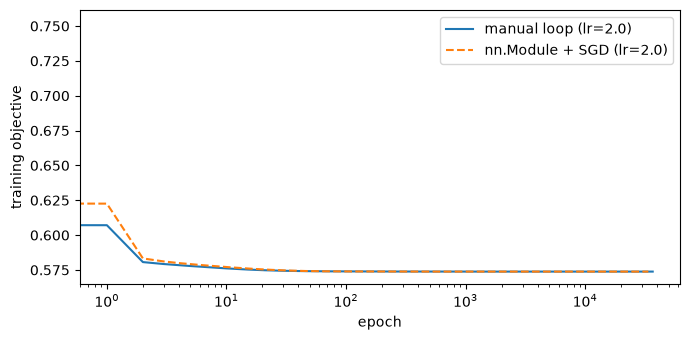

In [12]:
MAX_EPOCHS = 50_000
w_manual, b_manual, hist_manual, gn_manual = train_manual(LR_MANUAL, MAX_EPOCHS)
module, hist_module, gn_module = train_module(LR_MODULE, MAX_EPOCHS)
print(f"manual: {len(hist_manual)} epochs, final grad norm {gn_manual:.1e}")
print(f"module: {len(hist_module)} epochs, final grad norm {gn_module:.1e}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(hist_manual, label=f"manual loop (lr={LR_MANUAL})")
ax.plot(hist_module, label=f"nn.Module + SGD (lr={LR_MODULE})", ls="--")
ax.set_xscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("training objective")
ax.legend()
fig.tight_layout()
fig.savefig(ART / "loss_curves.png", dpi=120)

## Do the three agree?

In [13]:
def params_sklearn():
    return sk_model.coef_.ravel(), float(sk_model.intercept_[0])


def params_manual():
    return w_manual.numpy(), float(b_manual.item())


def params_module():
    return module.linear.weight.detach().numpy().ravel(), float(module.linear.bias.item())


PARAMS = {"sklearn": params_sklearn(), "manual": params_manual(), "module": params_module()}


def predict(name, X):
    w, b = PARAMS[name]
    return 1 / (1 + np.exp(-(X @ w + b)))


def objective_and_grad(w, b):
    w = torch.tensor(w, requires_grad=True)
    b = torch.tensor([b], requires_grad=True)
    loss = objective(w, b, Xt_tr, yt_tr, LAM)
    loss.backward()
    return loss.item(), torch.sqrt(w.grad @ w.grad + b.grad @ b.grad).item()


agree_rows = []
for name, (w, b) in PARAMS.items():
    obj, gn = objective_and_grad(w, b)
    agree_rows.append({"model": name, "training_objective": obj, "grad_norm_at_solution": gn})
agreement = pd.DataFrame(agree_rows).set_index("model")

pairs = [("sklearn", "manual"), ("sklearn", "module"), ("manual", "module")]
pair_rows = []
for a, c in pairs:
    pair_rows.append({
        "pair": f"{a} vs {c}",
        "max_abs_weight_diff": np.max(np.abs(np.append(*PARAMS[a]) - np.append(*PARAMS[c]))),
        "max_abs_test_prob_diff": np.max(np.abs(predict(a, X_te) - predict(c, X_te))),
    })
pair_diffs = pd.DataFrame(pair_rows).set_index("pair")

coefs = pd.DataFrame({name: np.append(w, b) for name, (w, b) in PARAMS.items()}, index=FEATURES + ["intercept"])
print(agreement.to_string(float_format=lambda v: f"{v:.3e}"))
print()
print(pair_diffs.to_string(float_format=lambda v: f"{v:.1e}"))
coefs.round(4)

         training_objective  grad_norm_at_solution
model                                             
sklearn           5.738e-01              3.309e-08
manual            5.738e-01              9.998e-09
module            5.738e-01              9.997e-09

                   max_abs_weight_diff  max_abs_test_prob_diff
pair                                                          
sklearn vs manual              7.4e-05                 2.8e-06
sklearn vs module              7.4e-05                 2.8e-06
manual vs module               5.2e-09                 2.0e-10


,sklearn,manual,module
log_recency,-0.0550,-0.0550,-0.0550
log_orders,-0.7666,-0.7666,-0.7666
log_revenue,-0.7139,-0.7139,-0.7139
log_avg_order,0.2851,0.2851,0.2851
log_lines_per_order,-0.1902,-0.1902,-0.1902
log_products,0.1306,0.1306,0.1306
days_since_first,0.1332,0.1332,0.1332
one_time,-0.0533,-0.0533,-0.0533
log_overdue,0.2014,0.2014,0.2014
recent_share,-0.0012,-0.0012,-0.0012


## Threshold from the voucher economics (validation)

The break-even probability assumes calibrated probabilities; the empirical optimum on
the validation snapshot checks it. Spend is each customer's own usual quarterly spend.

validation-optimal thresholds: {'sklearn': 0.38, 'manual': 0.38, 'module': 0.38} | break-even: 0.377


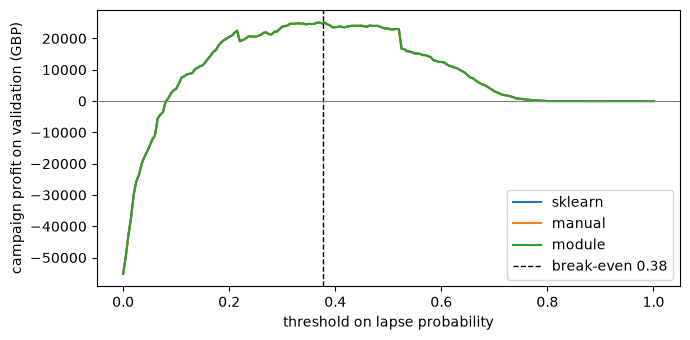

In [14]:
THRESHOLDS = np.round(np.linspace(0, 1, 201), 3)
spend_va, spend_te = (snaps.loc[m, "quarterly_spend"].to_numpy() for m in [is_val, is_test])


def profit_curve(p, y, spend):
    return np.array([voucher_profit(p >= t, y, spend, **COSTS) for t in THRESHOLDS])


val_curves = {name: profit_curve(predict(name, X_va), y_va, spend_va) for name in PARAMS}
T_CHOSEN = {name: float(THRESHOLDS[np.argmax(curve)]) for name, curve in val_curves.items()}
print("validation-optimal thresholds:", T_CHOSEN, f"| break-even: {T_BREAK_EVEN:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, curve in val_curves.items():
    ax.plot(THRESHOLDS, curve, label=name)
ax.axvline(T_BREAK_EVEN, color="k", ls="--", lw=1, label=f"break-even {T_BREAK_EVEN:.2f}")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("threshold on lapse probability")
ax.set_ylabel("campaign profit on validation (GBP)")
ax.legend()
fig.tight_layout()
fig.savefig(ART / "val_profit_curve.png", dpi=120)

## Baselines

- **Constant base rate** for the probability metrics (AUC 0.5).
- **Send to nobody** (profit 0, the reference) and **send to everyone**.
- **Recency rule** — "voucher to anyone who hasn't ordered for R days", the rule a
  marketing team would use without a model. R is tuned on validation like our threshold.

In [15]:
recency_va = snaps.loc[is_val, "recency_days"].to_numpy()
recency_te = snaps.loc[is_test, "recency_days"].to_numpy()
R_GRID = np.arange(0, LOOKBACK_DAYS + 1, 5)
r_profit = [voucher_profit(recency_va >= r, y_va, spend_va, **COSTS) for r in R_GRID]
R_BEST = int(R_GRID[int(np.argmax(r_profit))])
print(f"recency rule: send if no order for >= {R_BEST} days")

base_rate = y_tr.mean()

recency rule: send if no order for >= 40 days


## Test-set results (touched once)

In [16]:
def evaluate(p, send):
    return {
        "auc": roc_auc_score(y_te, p),
        "log_loss": log_loss(y_te, np.clip(p, 1e-12, 1 - 1e-12)),
        "brier": brier_score_loss(y_te, p),
        "vouchers_sent": int(np.sum(send)),
        "precision_of_sent": float(y_te[send].mean()) if np.any(send) else float("nan"),
        "profit_gbp": voucher_profit(send, y_te, spend_te, **COSTS),
    }


results = {}
for name in PARAMS:
    p = predict(name, X_te)
    results[name] = evaluate(p, p >= T_CHOSEN[name])
const = np.full(len(y_te), base_rate)
results["baseline: send to nobody"] = evaluate(const, np.zeros(len(y_te), bool))
results["baseline: send to everyone"] = evaluate(const, np.ones(len(y_te), bool))
results[f"baseline: recency >= {R_BEST}d"] = evaluate(const, recency_te >= R_BEST)
for k in ["auc", "log_loss", "brier"]:  # a rule gives no probabilities to score
    results[f"baseline: recency >= {R_BEST}d"][k] = float("nan")

results_df = pd.DataFrame(results).T
results_df.round(4)

,auc,log_loss,brier,vouchers_sent,precision_of_sent,profit_gbp
sklearn,0.7371,0.5777,0.1997,1497.0,0.5511,9771.6905
manual,0.7371,0.5777,0.1997,1497.0,0.5511,9771.6905
module,0.7371,0.5777,0.1997,1497.0,0.5511,9771.6905
baseline: send to nobody,0.5000,0.7061,0.2565,0.0,NaN,0.0000
baseline: send to everyone,0.5000,0.7061,0.2565,2768.0,0.3931,-95687.4375
baseline: recency >= 40d,NaN,NaN,NaN,1653.0,0.4797,691.4679


### Is the profit gap real? Bootstrap over test customers

In [17]:
rng = np.random.default_rng(SEED)
p_sk = predict("sklearn", X_te)
send_model = p_sk >= T_CHOSEN["sklearn"]
send_rule = recency_te >= R_BEST
diffs = []
for _ in range(2_000):
    i = rng.integers(0, len(y_te), len(y_te))
    diffs.append(
        voucher_profit(send_model[i], y_te[i], spend_te[i], **COSTS)
        - voucher_profit(send_rule[i], y_te[i], spend_te[i], **COSTS)
    )
ci = np.percentile(diffs, [2.5, 97.5])
print(f"model minus recency rule: {np.mean(diffs):,.0f} GBP, 95% CI [{ci[0]:,.0f}, {ci[1]:,.0f}]")

model minus recency rule: 9,122 GBP, 95% CI [699, 15,445]


### How much does the answer depend on the economics?

For each assumption, re-pick the threshold and the recency rule on validation, then
score both on test. Same trained model throughout: only the decision layer changes.

In [18]:
p_va_sk = predict("sklearn", X_va)
sens_rows = []
for L in [1, 2, 4, 6]:
    for s in [0.05, 0.15, 0.25]:
        costs = {**COSTS, "retained_quarters": L, "save_rate": s}
        t = THRESHOLDS[np.argmax([voucher_profit(p_va_sk >= t, y_va, spend_va, **costs) for t in THRESHOLDS])]
        r = R_GRID[np.argmax([voucher_profit(recency_va >= r, y_va, spend_va, **costs) for r in R_GRID])]
        sens_rows.append({
            "retained_quarters": L, "save_rate": s,
            "break_even": break_even_threshold(DISCOUNT, MARGIN, s, L), "val_threshold": t,
            "test_profit_model": voucher_profit(p_sk >= t, y_te, spend_te, **costs),
            "test_profit_recency_rule": voucher_profit(recency_te >= r, y_te, spend_te, **costs),
        })
sensitivity = pd.DataFrame(sens_rows)
sensitivity.round(3)

,retained_quarters,save_rate,break_even,val_threshold,test_profit_model,test_profit_recency_rule
0,1,0.05,0.909,0.900,0.000,0.000
1,1,0.15,0.769,0.900,0.000,0.000
2,1,0.25,0.667,0.900,0.000,-924.791
3,2,0.05,0.800,0.900,0.000,0.000
4,2,0.15,0.571,0.520,-504.775,-62.007
5,2,0.25,0.444,0.480,2817.289,2459.869
6,4,0.05,0.645,0.640,-40.007,-1079.551
7,4,0.15,0.377,0.380,9771.690,691.468
8,4,0.25,0.267,0.215,29556.703,20767.993
9,6,0.05,0.541,0.520,38.157,-1037.771


### Calibration on test

The threshold rule only works if 0.8 means 80%. Validation and test come from
different quarters, so this also checks whether the season dummies carried over.

test: mean predicted 0.381 vs observed lapse rate 0.393 | ECE 0.023


,mean_predicted,observed,n
"(-7.400000000000006e-05, 0.105]",0.055,0.036,277
"(0.105, 0.178]",0.141,0.141,277
"(0.178, 0.254]",0.216,0.209,277
"(0.254, 0.329]",0.292,0.337,276
"(0.329, 0.415]",0.371,0.394,277
"(0.415, 0.486]",0.454,0.505,277
"(0.486, 0.527]",0.508,0.486,276
"(0.527, 0.56]",0.545,0.567,277
"(0.56, 0.601]",0.579,0.574,277
"(0.601, 0.815]",0.646,0.682,277


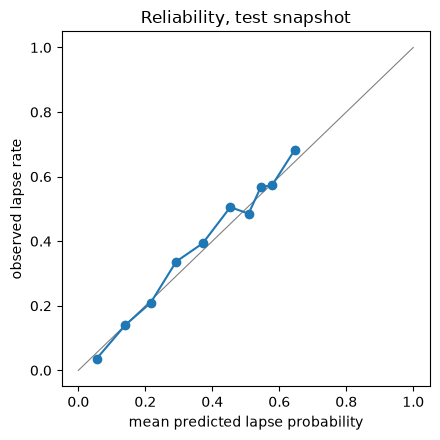

In [19]:
bins = pd.qcut(p_sk, 10, duplicates="drop")
calib = pd.DataFrame({"p": p_sk, "y": y_te}).groupby(bins, observed=True).agg(mean_predicted=("p", "mean"), observed=("y", "mean"), n=("y", "size"))
ece = float(np.sum(calib["n"] / calib["n"].sum() * np.abs(calib["observed"] - calib["mean_predicted"])))
print(f"test: mean predicted {p_sk.mean():.3f} vs observed lapse rate {y_te.mean():.3f} | ECE {ece:.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.plot(calib["mean_predicted"], calib["observed"], marker="o")
ax.set_xlabel("mean predicted lapse probability")
ax.set_ylabel("observed lapse rate")
ax.set_title("Reliability, test snapshot")
fig.tight_layout()
fig.savefig(ART / "calibration.png", dpi=120)
calib.round(3)

## Save artifacts for the dashboard

The app loads these and never fits anything.

In [20]:
joblib.dump(sk_model, ART / "sklearn_logreg.joblib")
joblib.dump(scaler, ART / "scaler.joblib")
torch.save({"w": w_manual, "b": b_manual}, ART / "manual_torch.pt")
torch.save(module.state_dict(), ART / "torch_module.pt")

keep_cols = ["customer", "cutoff", "split", "season", "lapsed", "recency_days", "n_orders", "revenue",
             "quarterly_spend", "n_products", "xmas_share", "return_rate", "uk"]
dashboard_data = pd.concat([snaps[keep_cols], X_all[FEATURES].add_prefix("f_")], axis=1)
dashboard_data.to_csv(ART / "snapshots.csv.gz", index=False)

config = {
    "features": FEATURES,
    "lookback_days": LOOKBACK_DAYS,
    "horizon_days": HORIZON_DAYS,
    "cutoffs": {"train": TRAIN_CUTOFFS, "val": VAL_CUTOFF, "test": TEST_CUTOFF},
    "costs": COSTS,
    "break_even_threshold": T_BREAK_EVEN,
    "chosen_thresholds": T_CHOSEN,
    "recency_rule_days": R_BEST,
    "C": C_BEST,
    "lam": LAM,
    "lr": {"manual": LR_MANUAL, "module": LR_MODULE},
}
(ART / "config.json").write_text(json.dumps(config, indent=2))

metrics = {
    "cleaning_steps": steps,
    "ablation": ablation.to_dict(orient="records"),
    "c_search": c_search.to_dict(orient="records"),
    "lr_search": lr_search.to_dict(orient="records"),
    "agreement": agreement.reset_index().to_dict(orient="records"),
    "pair_diffs": pair_diffs.reset_index().to_dict(orient="records"),
    "test_results": results_df.reset_index(names="model").to_dict(orient="records"),
    "bootstrap_model_minus_rule": {"mean": float(np.mean(diffs)), "ci95": [float(ci[0]), float(ci[1])]},
    "sensitivity": sensitivity.to_dict(orient="records"),
    "calibration": {"ece": ece, "mean_predicted": float(p_sk.mean()), "observed": float(y_te.mean())},
    "epochs": {"manual": len(hist_manual), "module": len(hist_module)},
}
(ART / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
(ART / "loss_history.json").write_text(json.dumps({"manual": hist_manual, "module": hist_module}))
print("saved:", sorted(p.name for p in ART.iterdir()))

saved: ['calibration.png', 'config.json', 'loss_curves.png', 'loss_history.json', 'manual_torch.pt', 'metrics.json', 'scaler.joblib', 'sklearn_logreg.joblib', 'snapshots.csv.gz', 'torch_module.pt', 'val_profit_curve.png']
